# EDA — Exploratory Data Analysis
### Data Science Core Concepts 101 — by Yunhan Jin

EDA is the first thing you do after getting data. The goal is to understand what you have before modeling anything.

---

## Section 1: Loading & Inspecting Data

### 1.1 Setup
We use a synthetic housing dataset throughout this notebook — realistic enough to demonstrate all core EDA patterns. It includes missing values and duplicate rows intentionally.

In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 200

neighborhoods = ['Downtown', 'Midtown', 'Uptown', 'Suburbs']
base_prices = {'Downtown': 800000, 'Midtown': 600000, 'Uptown': 500000, 'Suburbs': 350000}

records = []
for i in range(n):
    nbhd = np.random.choice(neighborhoods)
    sqft = max(600, int(np.random.normal(1500, 400)))
    price = int(base_prices[nbhd] + sqft * 150 + np.random.normal(0, 50000))
    records.append({
        'id':           i + 1,
        'price':        price,
        'sqft':         sqft,
        'bedrooms':     np.random.choice([1, 2, 3, 4, 5], p=[0.1, 0.25, 0.35, 0.2, 0.1]),
        'bathrooms':    np.random.choice([1.0, 1.5, 2.0, 2.5, 3.0]),
        'neighborhood': nbhd,
        'year_built':   int(np.random.normal(1990, 20)),
        'has_garage':   np.random.choice([True, False], p=[0.6, 0.4])
    })

df = pd.DataFrame(records)

# Introduce missing values
df.loc[np.random.choice(n, 15, replace=False), 'bathrooms'] = np.nan
df.loc[np.random.choice(n, 10, replace=False), 'year_built'] = np.nan

# Introduce duplicate rows
df = pd.concat([df, df.sample(5, random_state=42)], ignore_index=True)

print(f"Dataset shape: {df.shape}")

Dataset shape: (205, 8)


### 1.2 Loading Data
In practice, data comes from files. `pandas` handles the most common formats.

In [2]:
# CSV — most common format in DS
# df = pd.read_csv('housing.csv')

# Excel
# df = pd.read_excel('housing.xlsx', sheet_name='Sheet1')

# JSON
# df = pd.read_json('housing.json')

# From a SQL query (using our SQLite connection from the SQL notebook)
# df = pd.read_sql("SELECT * FROM employees", conn)

# Save to CSV
# df.to_csv('output.csv', index=False)

print("Common loading patterns shown above — using synthetic dataset for this notebook.")

Common loading patterns shown above — using synthetic dataset for this notebook.


### 1.3 First Look
The first thing you do with any new dataset — understand its shape, types, and a sample of values.

In [3]:
# Preview first and last rows
df.head()    # first 5 rows

,id,price,sqft,bedrooms,bathrooms,neighborhood,year_built,has_garage
0,1,717621,1279,4,3.0,Uptown,1985.0,True
1,2,516638,1406,3,3.0,Suburbs,1981.0,False
2,3,554810,1508,3,2.5,Suburbs,1994.0,True
3,4,501580,1192,3,3.0,Suburbs,1992.0,True
4,5,836221,1259,1,2.5,Midtown,2005.0,False


In [4]:
print(df.shape)   # (rows, columns)
print()
print(df.dtypes)  # data type of each column

(205, 8)

id                int64
price             int64
sqft              int64
bedrooms          int64
bathrooms       float64
neighborhood        str
year_built      float64
has_garage         bool
dtype: object


In [5]:
df.describe()  # summary statistics for numeric columns

,id,price,sqft,bedrooms,bathrooms,year_built
count,205.000000,2.050000e+02,205.000000,205.000000,190.000000,194.000000
mean,100.151220,8.033669e+05,1509.736585,2.902439,2.002632,1992.170103
std,57.855902,1.910546e+05,405.029797,1.043300,0.728297,19.564347
min,1.000000,4.438010e+05,600.000000,1.000000,1.000000,1937.000000
25%,50.000000,6.474920e+05,1253.000000,2.000000,1.500000,1980.000000
50%,100.000000,8.138610e+05,1508.000000,3.000000,2.000000,1991.000000
75%,150.000000,9.486330e+05,1785.000000,4.000000,2.500000,2007.000000
max,200.000000,1.216004e+06,2769.000000,5.000000,3.000000,2045.000000


In [6]:
df.info()  # column types + non-null counts in one view

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            205 non-null    int64  
 1   price         205 non-null    int64  
 2   sqft          205 non-null    int64  
 3   bedrooms      205 non-null    int64  
 4   bathrooms     190 non-null    float64
 5   neighborhood  205 non-null    str    
 6   year_built    194 non-null    float64
 7   has_garage    205 non-null    bool   
dtypes: bool(1), float64(2), int64(4), str(1)
memory usage: 13.0 KB


### 1.4 Missing Values
Missing data is the norm, not the exception. Always check before doing anything else.

In [7]:
# Count missing values per column
df.isnull().sum()

id               0
price            0
sqft             0
bedrooms         0
bathrooms       15
neighborhood     0
year_built      11
has_garage       0
dtype: int64

In [8]:
# As a percentage
(df.isnull().sum() / len(df) * 100).round(1)

id              0.0
price           0.0
sqft            0.0
bedrooms        0.0
bathrooms       7.3
neighborhood    0.0
year_built      5.4
has_garage      0.0
dtype: float64

In [9]:
# Option 1: fill with a value
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].median())

# Option 2: drop rows with any missing values
df_clean = df.dropna()

# Option 3: drop rows missing a specific column
df_clean = df.dropna(subset=['year_built'])

print(f"Original: {df.shape}, After dropna: {df_clean.shape}")

Original: (205, 8), After dropna: (194, 8)


---
## Section 2: Cleaning Data

### 2.1 Duplicates
Duplicate rows silently distort aggregations, model training, and train/test splits.

In [10]:
# Check for duplicates
print(f"Duplicate rows: {df.duplicated().sum()}")

# Drop duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(f"After dedup: {df.shape}")

Duplicate rows: 5
After dedup: (200, 8)


### 2.2 Data Type Fixes
Columns often come in as the wrong type — strings that should be numbers, floats that should be ints, etc.

In [11]:
# Cast to correct types
df['year_built'] = df['year_built'].astype('Int64')  # Int64 supports NaN, int64 does not
df['has_garage'] = df['has_garage'].astype(bool)

# Convert a string column to datetime (common with date columns)
# df['date'] = pd.to_datetime(df['date'])

df.dtypes

id                int64
price             int64
sqft              int64
bedrooms          int64
bathrooms       float64
neighborhood        str
year_built        Int64
has_garage         bool
dtype: object

### 2.3 Renaming & Selecting Columns

In [12]:
# Rename columns
df = df.rename(columns={'sqft': 'sq_ft', 'neighborhood': 'nbhd'})

# Select specific columns
df[['price', 'sq_ft', 'nbhd']].head(3)

,price,sq_ft,nbhd
0,717621,1279,Uptown
1,516638,1406,Suburbs
2,554810,1508,Suburbs


In [13]:
# Drop columns
df = df.drop(columns=['id'])
df.head(3)

,price,sq_ft,bedrooms,bathrooms,nbhd,year_built,has_garage
0,717621,1279,4,3.0,Uptown,1985,True
1,516638,1406,3,3.0,Suburbs,1981,False
2,554810,1508,3,2.5,Suburbs,1994,True


### 2.4 Filtering & Sorting

In [14]:
# Filter rows
downtown = df[df['nbhd'] == 'Downtown']
expensive = df[df['price'] > 900000]

# Multiple conditions
large_downtown = df[(df['nbhd'] == 'Downtown') & (df['sq_ft'] > 1500)]

print(f"Downtown: {len(downtown)}, Expensive: {len(expensive)}, Large Downtown: {len(large_downtown)}")

Downtown: 56, Expensive: 65, Large Downtown: 24


In [15]:
# Sort
df.sort_values('price', ascending=False).head(5)

,price,sq_ft,bedrooms,bathrooms,nbhd,year_built,has_garage
30,1216004,1753,3,3.0,Downtown,2008,True
103,1173796,2383,3,3.0,Downtown,<NA>,False
189,1166135,1918,3,2.5,Downtown,1959,True
91,1164278,2263,1,3.0,Downtown,1986,True
31,1159921,1488,3,3.0,Downtown,1991,True


---
## Section 3: Visualization
*A plot reveals what a summary statistic can hide.*

### 3.1 Setup

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

### 3.2 Distributions
Always start by understanding how your key numeric variables are distributed.

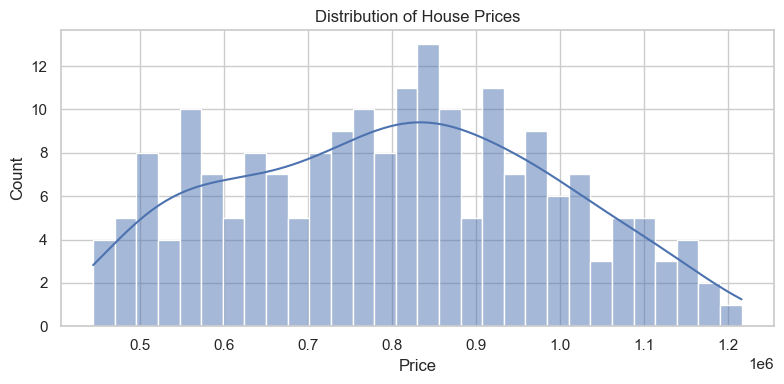

In [17]:
# Histogram — distribution of price
plt.figure(figsize=(8, 4))
sns.histplot(df['price'], bins=30, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Price')
plt.tight_layout()
plt.show()

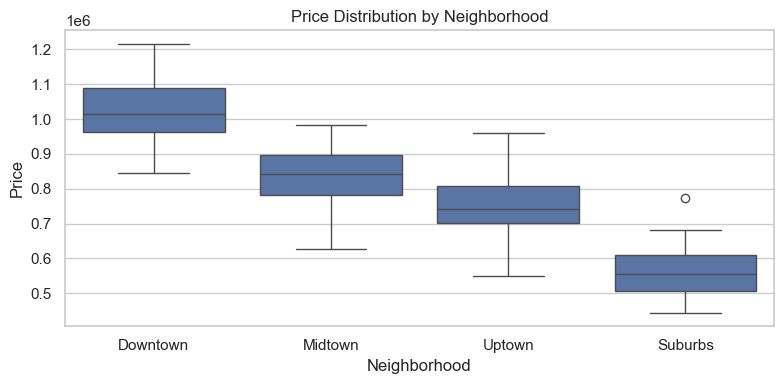

In [18]:
# Boxplot — price distribution by neighborhood
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='nbhd', y='price', order=['Downtown', 'Midtown', 'Uptown', 'Suburbs'])
plt.title('Price Distribution by Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

### 3.3 Relationships
Scatter plots and correlation heatmaps reveal how variables relate to each other.

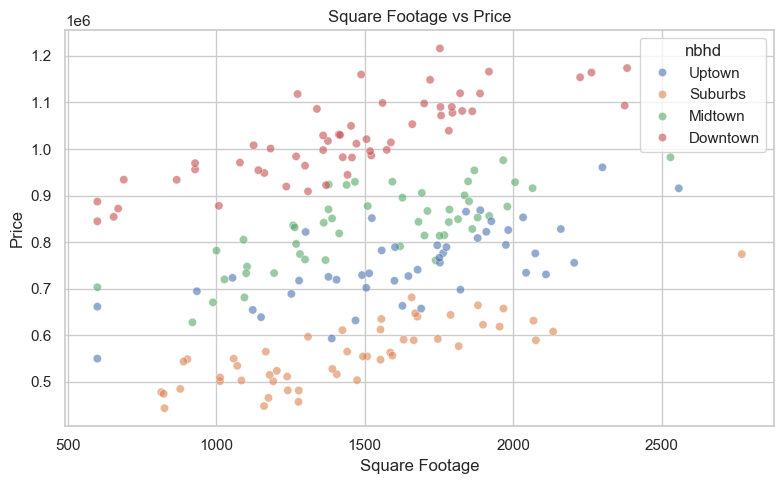

In [19]:
# Scatter — sqft vs price, colored by neighborhood
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='sq_ft', y='price', hue='nbhd', alpha=0.6)
plt.title('Square Footage vs Price')
plt.xlabel('Square Footage')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

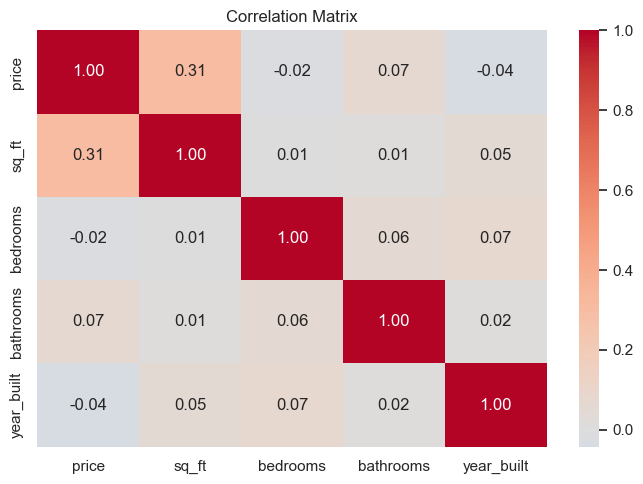

In [20]:
# Correlation heatmap — numeric columns only
numeric_cols = df.select_dtypes(include='number')

plt.figure(figsize=(7, 5))
sns.heatmap(numeric_cols.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

### 3.4 Categorical Breakdowns
Bar charts are the go-to for comparing a metric across categories.

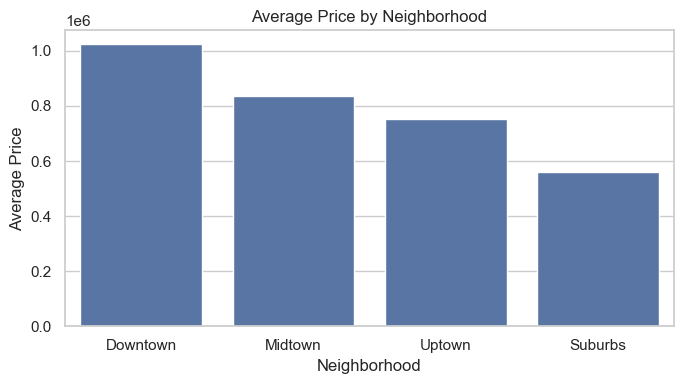

In [21]:
# Average price by neighborhood
avg_price = df.groupby('nbhd')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=avg_price.index, y=avg_price.values)
plt.title('Average Price by Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

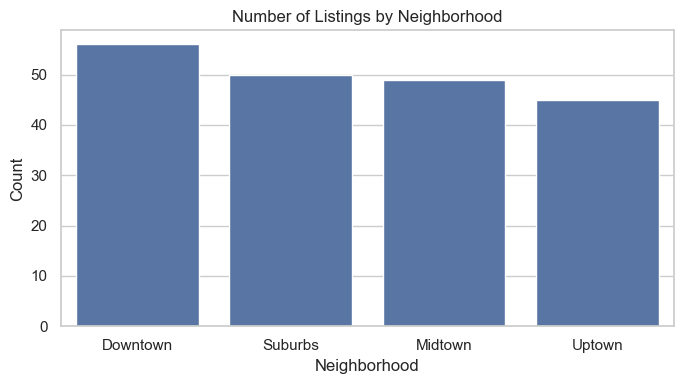

In [22]:
# Count of listings by neighborhood
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='nbhd', order=df['nbhd'].value_counts().index)
plt.title('Number of Listings by Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('Count')
plt.tight_layout()
plt.show()